# 03 Call list: from probabilities to an action

The model gives each customer a churn probability. The retention team needs something else: **a ranked list of who to contact, and how**.

`expected loss = probability of churning x customer value`

A customer with a 90% chance of leaving who is worth very little is a smaller risk than a customer with a 40% chance who is worth twenty times more. Ranking by probability alone ignores that.

The customers scored here are the **test set**: the model never saw them during training, so this is an honest preview of what the list would look like in use. In production the same steps would run on the whole active base every quarter.

In [1]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

import json
import numpy as np
import pandas as pd

test = pd.read_csv("../data/processed/test_scored.csv")
settings = json.load(open("../data/processed/decision_settings.json"))
THRESHOLD, CAPACITY = settings["threshold"], int(settings["capacity_test"])
test["expected_loss"] = test.p_churn * test.customer_value
test.sort_values("expected_loss", ascending=False).head(10).round(3)

,customer_id,churn,customer_value,p_churn,flagged,expected_loss
280,C0689,1,978.390,0.663,True,649.066
543,C1139,0,909.135,0.660,True,599.665
19,C1089,1,883.800,0.622,True,549.642
230,C1075,1,337.725,0.948,True,320.305
281,C0225,1,334.530,0.908,True,303.660
40,C0678,1,272.120,0.914,True,248.816
479,C0478,1,336.880,0.738,True,248.464
691,C0878,1,289.320,0.850,True,245.822
359,C1528,1,296.440,0.823,True,244.033
2,C1537,1,288.320,0.836,True,240.982


## 1. Does ranking by expected loss actually protect more value?

In [2]:
rng = np.random.default_rng(42)
total_lost = test.loc[test.churn == 1, "customer_value"].sum()

def captured(order):
    lost = np.where(test.loc[order, "churn"] == 1, test.loc[order, "customer_value"], 0)
    return np.concatenate([[0], np.cumsum(lost)]) / total_lost

by_loss = captured(test.sort_values("expected_loss", ascending=False).index)
by_prob = captured(test.sort_values("p_churn", ascending=False).index)
by_random = np.mean([captured(rng.permutation(test.index)) for _ in range(200)], axis=0)

for name, curve in [("expected loss", by_loss), ("probability", by_prob), ("random", by_random)]:
    print(f"Top {CAPACITY} by {name:13s} -> {curve[CAPACITY]:.0%} of the value at risk from churners")

Top 75 by expected loss -> 82% of the value at risk from churners
Top 75 by probability   -> 58% of the value at risk from churners
Top 75 by random        -> 10% of the value at risk from churners


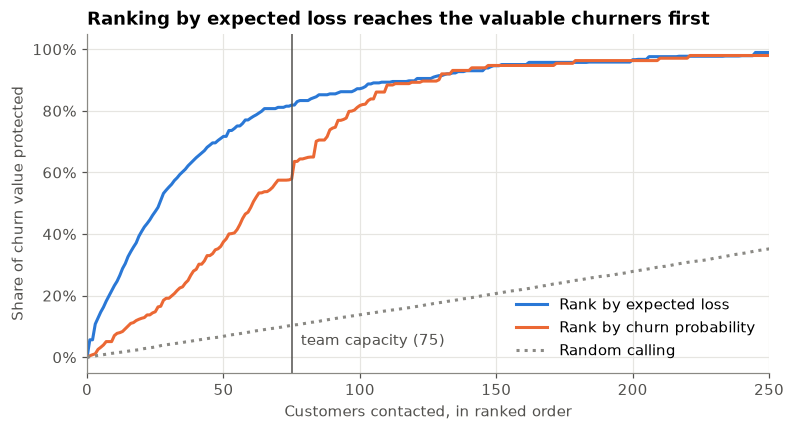

In [3]:
n = np.arange(len(by_loss))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(n, by_loss, color=BLUE, label="Rank by expected loss")
ax.plot(n, by_prob, color=ORANGE, label="Rank by churn probability")
ax.plot(n, by_random, color=GREY, linestyle=":", label="Random calling")
ax.axvline(CAPACITY, color="#52514e", linewidth=1)
ax.annotate(f"team capacity ({CAPACITY})", (CAPACITY, 0.04), xytext=(6, 0), textcoords="offset points", color="#52514e")
ax.set_xlim(0, 250)
ax.set_xlabel("Customers contacted, in ranked order")
ax.set_ylabel("Share of churn value protected")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Ranking by expected loss reaches the valuable churners first")
ax.legend(loc="lower right")
fig.savefig("../figures/value_captured_by_ranking.png")
plt.show()

## 2. Retention tiers

Only customers above the cost-based threshold from Step 6 are worth contacting at all. Among them, expected loss sets the order:

- **Tier 1, personal call:** the 50 eligible customers with the highest expected loss. A trained agent calls, with authority to offer an upgrade or discount.
- **Tier 2, targeted offer:** the next eligible customers, up to the team's capacity. An SMS or email with a bonus data offer.
- **Tier 3, automated nudge:** remaining eligible customers beyond capacity. A low-cost automated message, no agent time.
- **No action:** everyone below the threshold. Contacting them costs more than it is expected to save.

In [4]:
ranked = test.assign(eligible=test.p_churn >= THRESHOLD)
ranked = ranked.sort_values(["eligible", "expected_loss"], ascending=[False, False]).reset_index(drop=True)
ranked["rank"] = ranked.index + 1
ranked["tier"] = np.select(
    [~ranked.eligible, ranked["rank"] <= 50, ranked["rank"] <= CAPACITY],
    ["No action", "1 Personal call", "2 Targeted offer"], default="3 Automated nudge")

tiers = ranked.groupby("tier").agg(customers=("customer_id", "size"), actual_churners=("churn", "sum"),
                                   mean_p_churn=("p_churn", "mean"), mean_value=("customer_value", "mean"),
                                   expected_loss=("expected_loss", "sum"))
tiers["churner_hit_rate"] = tiers.actual_churners / tiers.customers
tiers.round(2)

,customers,actual_churners,mean_p_churn,mean_value,expected_loss,churner_hit_rate
tier,,,,,,
1 Personal call,50,48,0.78,274.05,9974.88,0.96
2 Targeted offer,25,19,0.64,152.74,1898.76,0.76
3 Automated nudge,74,39,0.53,56.29,1703.76,0.53
No action,564,6,0.03,553.00,3293.55,0.01


## 3. Budget buffer: how much is a contact worth?

The most it makes sense to spend on contacting a customer is the value you expect to save:

`maximum spend = p(churn) x save rate x value if saved`

Using the README assumptions (30% save rate, R3,000 per saved customer), a customer at 90% churn risk justifies up to R810, and one at 20% only R180. Spending R140 on a customer below the break-even probability loses money on average. The R3,000 is an average; for a customer worth twice the average, the ceiling doubles.

In [5]:
SAVE_RATE, VALUE_IF_SAVED = 0.30, 3000
ranked["max_spend_rand"] = (ranked.p_churn * SAVE_RATE * VALUE_IF_SAVED).round(0)
ranked.groupby("tier")["max_spend_rand"].agg(["min", "median", "max"])

,min,median,max
tier,,,
1 Personal call,250.0,730.0,866.0
2 Targeted offer,212.0,634.0,879.0
3 Automated nudge,211.0,404.5,871.0
No action,0.0,5.0,206.0


## 4. Export the top 50 call list

In [6]:
call_list = ranked.head(50)[["rank", "customer_id", "p_churn", "customer_value", "expected_loss", "max_spend_rand", "tier"]]
call_list = call_list.round({"p_churn": 3, "customer_value": 2, "expected_loss": 2})
call_list.to_csv("../reports/call_list_top50.csv", index=False)
hits = ranked.head(50).churn.mean()
print(f"Saved reports/call_list_top50.csv. In hindsight, {hits:.0%} of these 50 customers did churn.")
call_list.head(10)

Saved reports/call_list_top50.csv. In hindsight, 96% of these 50 customers did churn.


,rank,customer_id,p_churn,customer_value,expected_loss,max_spend_rand,tier
0,1,C0689,0.663,978.39,649.07,597.0,1 Personal call
1,2,C1139,0.660,909.14,599.67,594.0,1 Personal call
2,3,C1089,0.622,883.80,549.64,560.0,1 Personal call
3,4,C1075,0.948,337.72,320.30,854.0,1 Personal call
4,5,C0225,0.908,334.53,303.66,817.0,1 Personal call
5,6,C0678,0.914,272.12,248.82,823.0,1 Personal call
6,7,C0478,0.738,336.88,248.46,664.0,1 Personal call
7,8,C0878,0.850,289.32,245.82,765.0,1 Personal call
8,9,C1528,0.823,296.44,244.03,741.0,1 Personal call
9,10,C1537,0.836,288.32,240.98,752.0,1 Personal call
